# Procedure families compared: Ajuste Direto vs Concurso público vs Consulta Prévia

Three families defined by accent-folded, lowercased prefix of `tipo_procedimento`. Everything else is `other`
(framework agreements, excluded contracting, limited tender, …). Entities are keyed by NIPC; the `-` sentinel
falls back to name similarity (`key_source`).

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl
from base_gov.entities import (
    canonical_names,
    entity_key,
    explode_entities,
    normalize_name,
    split_packed,
)

from base_gov.stats import value_impact, value_per_day

DATA = Path("..") / "data"
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_width_chars(140)
plt.rcParams["figure.figsize"] = (10, 4)

In [2]:
contracts_raw = pl.read_parquet(DATA / "contracts.parquet")
print(f"rows={contracts_raw.height:,}  cols={contracts_raw.width}")


contracts_all = (
    entity_key(
        contracts_raw.with_columns(split_packed("adjudicante", prefix="adjudicante")),
        prefix="adjudicante",
    )
    .select(
        pl.col("idcontrato"),
        pl.col("adjudicante"),
        pl.col("adjudicante_nipc"),
        pl.col("adjudicante_name"),
        pl.col("adjudicante_key"),
        pl.col("adjudicante_key_source"),
        pl.col("adjudicatarios"),
        pl.col("objectoContrato").alias("objecto_contrato"),
        pl.col("precoContratual").alias("preco_contratual"),
        pl.col("prazoExecucao").alias("prazo_execucao"),
        pl.col("dataCelebracaoContrato").alias("data_celebracao"),
        pl.col("CPV").alias("cpv"),
        pl.col("NUTs").alias("nuts"),
        pl.col("Ano").alias("ano"),
        pl.col("tipoContrato").alias("tipo_contrato"),
        pl.col("tipoprocedimento").alias("tipo_procedimento"),
        
)
)
contracts_all = contracts_all.with_columns(value_per_day())
# Disregard contracts priced below MIN_VALUE (€); contracts_all keeps them for before/after comparisons.
MIN_VALUE = 10
contracts = contracts_all.filter(pl.col("preco_contratual") >= MIN_VALUE)
print(f"disregarded {contracts_all.height - contracts.height:,} contracts with preco_contratual < €{MIN_VALUE} "
      f"({(contracts_all.height - contracts.height) / contracts_all.height:.2%}); kept {contracts.height:,}")
print(f"valor_por_dia defined for {contracts['valor_por_dia'].is_not_null().mean():.1%} of kept contracts "
      f"(needs 1 <= prazo_execucao <= 3650 days)")
contracts.head()
print(contracts["adjudicante_key_source"].value_counts(sort=True))

FAMILIES = ["ajuste_direto", "concurso_publico", "consulta_previa"]

rows=409,344  cols=39
disregarded 1,490 contracts with preco_contratual < €10 (0.36%); kept 407,854
valor_por_dia defined for 98.9% of kept contracts (needs 1 <= prazo_execucao <= 3650 days)
shape: (2, 2)
┌────────────────────────┬────────┐
│ adjudicante_key_source ┆ count  │
│ ---                    ┆ ---    │
│ str                    ┆ u32    │
╞════════════════════════╪════════╡
│ nipc                   ┆ 407852 │
│ name                   ┆ 2      │
└────────────────────────┴────────┘


In [3]:
contracts_raw.filter(pl.col("precoContratual") < 1)

idcontrato,nAnuncio,TipoAnuncio,idINCM,tipoContrato,idprocedimento,tipoprocedimento,objectoContrato,descContrato,adjudicante,adjudicatarios,dataPublicacao,dataCelebracaoContrato,precoContratual,CPV,prazoExecucao,LocalExecucao,fundamentacao,ProcedimentoCentralizado,numAcordoQuadro,DescrAcordoQuadro,precoBaseProcedimento,dataDecisaoAdjudicacao,dataFechoContrato,PrecoTotalEfetivo,regime,justifNReducEscrContrato,tipoFimContrato,CritMateriais,concorrentes,linkPecasProc,Observacoes,ContratEcologico,fundamentAjusteDireto,Ano,adjudicatarioPMEs,NUTs,Lotes,TipoCriterioAdjudicacao
i64,str,str,i64,str,i64,str,str,str,str,str,date,date,f64,str,i64,str,str,str,i64,str,f64,date,date,f64,str,str,str,str,str,str,str,str,str,i64,str,str,str,str
11316553,"""""",null,null,"""Aquisição de serviços""",7541004,"""Ajuste Direto Regime Geral""","""Aquisição de serviços de consu…","""Aquisição de serviços de consu…","""506807720 - APCV - Associação …","""500906181 - SABSEG - CORRETOR …",2025-03-31,2025-03-28,0.0,"""66518000-4 - Serviços de corre…",1096,"""Portugal, Viseu, Viseu""","""Artigo 20.º, n.º 1, alínea d) …","""Não""",null,null,0.0,2025-03-24,null,0.0,"""Código dos Contratos Públicos …",null,null,"""Não""",null,null,null,"""Não""",null,2025,null,null,null,"""Monofator"""
11801398,"""""",null,null,"""Aquisição de bens móveis""",7919011,"""Ajuste Direto Regime Geral""","""61/8072/2025 - Autorização de …","""Autorização de Utilização Exce…","""510745997 - Unidade Local de S…","""500134960 - SANOFI- PRODUTOS F…",2025-10-17,2025-10-07,0.2,"""33600000-6 - Produtos farmacêu…",92,"""Portugal, Faro, Faro""","""Artigo 24.º, n.º 4 do Código d…","""Não""",null,null,0.2,2025-10-07,null,0.0,"""Código dos Contratos Públicos …","""Artigo 95.º, n.º 1, a), contra…",null,"""Sim""",null,null,null,"""Não""",null,2025,"""500134960""","""PT150 - Algarve""",null,"""Monofator"""
11517624,"""7034/2025""","""Anúncio de procedimento""",418835777,"""Aquisição de serviços""",7523790,"""Concurso público""","""Aquisição de serviços na área …","""Aquisição de serviços na área …","""500051054 - Município de Almad…","""504580485 - Sabseg - Mediação …",2025-06-12,2025-06-12,0.0,"""66518100-5 - Serviços de corre…",365,"""Portugal, Setúbal, Almada""","""Artigo 20.º, n.º 1, alínea b) …","""Não""",null,null,0.0,2025-06-02,null,0.0,"""Código dos Contratos Públicos …",null,null,"""Não""",null,"""https://community.vortal.biz/P…",null,"""Não""",null,2025,"""504580485""",null,null,"""Multifator"""
15471925,"""9103/2026""","""Anúncio de Alteração""",419957036,"""Empreitadas de obras públicas""",10021010,"""Concurso limitado por prévia q…","""Acordo Quadro para a Execução …","""Acordo Quadro para a Execução …","""505037238 - Gestão e Obras do …","""500326517 - CJR – Cândido José…",2026-08-10,2026-08-07,0.0,"""45233140-2 - Obras em estradas""",1440,"""Portugal, Porto, Porto""","""Artigo 19.º, alínea a) do Códi…","""Não""",null,null,2e7,2026-07-10,null,0.0,"""Código dos Contratos Públicos …",null,null,"""Não""","""501312412-ACA - Alberto Couto …","""https://www.acingov.pt/acingov…",null,"""Não""",null,2026,"""500326517""","""PT11A - Área Metropolitana do …","""Zona Oriental""","""Monofator"""
11578947,"""""",null,null,"""Aquisição de serviços""",7735883,"""Consulta Prévia""","""Aquisição de serviços de recol…","""Aquisição de serviços de recol…","""501306269 - Município de Ovar""","""501133747 - Luso Finsa - Indús…",2025-07-11,2025-07-03,0.0,"""90510000-5 - Tratamento e elim…",730,"""Portugal, Aveiro, Ovar""","""Artigo 20.º, n.º 1, alínea c) …","""Não""",null,null,0.0,2025-06-16,null,0.0,"""Código dos Contratos Públicos …",null,null,"""Não""","""501133747-Luso Finsa - Indústr…",null,null,"""Não""",null,2025,"""501133747""",null,null,"""Monofator"""
14489611,"""20727/2025""","""Anúncio de procedimento""",419387224,"""Concessão de serviços públicos""",7768054,"""Concurso público""","""Concessão de Lojas no Mercado …","""Concessão do direito de explor…","""510856861 - Freguesia de Aveni…","""- -

In [4]:
tp = (
    pl.col("tipo_procedimento").str.to_lowercase().str.replace_all("ú", "u").str.replace_all("é", "e")
)
FAMILY = (
    pl.when(tp.str.starts_with("ajuste direto")).then(pl.lit("ajuste_direto"))
    .when(tp.str.starts_with("concurso publico")).then(pl.lit("concurso_publico"))
    .when(tp.str.starts_with("consulta previa")).then(pl.lit("consulta_previa"))
    .otherwise(pl.lit("other"))
    .alias("family")
)
contracts_all = contracts_all.with_columns(FAMILY)
contracts = contracts.with_columns(FAMILY)
counts = contracts_all["family"].value_counts(sort=True)
display(counts)
fam_all = contracts_all.filter(pl.col("family").is_in(FAMILIES))  # before the €10 filter
fam = contracts.filter(pl.col("family").is_in(FAMILIES))
assert dict(zip(counts["family"], counts["count"])) == {
    "ajuste_direto": 180174, "consulta_previa": 69064, "concurso_publico": 63641, "other": contracts_all.height - fam_all.height,
}
print(f"three families cover {fam_all.height:,} of {contracts_all.height:,} rows ({fam_all.height / contracts_all.height:.1%}); after the €10 filter: {fam.height:,}")

family,count
str,u32
"""ajuste_direto""",180174
"""other""",96465
"""consulta_previa""",69064
"""concurso_publico""",63641


three families cover 312,879 of 409,344 rows (76.4%); after the €10 filter: 311,676


In [5]:
headline = (
    fam.group_by("family")
    .agg(
        pl.len().alias("n_contracts"),
        pl.col("preco_contratual").sum().round(0).alias("total_value"),
        pl.col("preco_contratual").mean().round(0).alias("mean_value"),
        pl.col("preco_contratual").median().alias("median_value"),
    )
    .with_columns(
        (pl.col("n_contracts") / pl.col("n_contracts").sum()).round(3).alias("count_share"),
        (pl.col("total_value") / pl.col("total_value").sum()).round(3).alias("value_share"),
    )
    .sort("n_contracts", descending=True)
)
headline

family,n_contracts,total_value,mean_value,median_value,count_share,value_share
str,u32,f64,f64,f64,f64,f64
"""ajuste_direto""",179626,5.2180e9,29049.0,8763.045,0.576,0.193
"""consulta_previa""",68947,2.4508e9,35546.0,23290.0,0.221,0.09
"""concurso_publico""",63103,1.9415e10,307673.0,51985.0,0.202,0.717


In [6]:
# Effect of disregarding contracts priced below €10, per family.
for f in FAMILIES:
    print(f)
    display(value_impact(fam_all.filter(pl.col("family") == f), fam.filter(pl.col("family") == f)))

ajuste_direto


metric,before,after,change,change_pct
str,f64,f64,f64,f64
"""n_contracts""",180174.0,179626.0,-548.0,-0.3
"""mean_value""",28960.429478,29049.009992,88.580514,0.31
"""median_value""",8730.0,8763.045,33.045,0.38
"""total_value""",5.2179e9,5.2180e9,41048.009999,0.0


concurso_publico


metric,before,after,change,change_pct
str,f64,f64,f64,f64
"""n_contracts""",63641.0,63103.0,-538.0,-0.85
"""mean_value""",305069.685697,307673.261553,2603.575856,0.85
"""median_value""",50655.0,51985.0,1330.0,2.63
"""total_value""",1.9415e10,1.9415e10,165956.34,0.0


consulta_previa


metric,before,after,change,change_pct
str,f64,f64,f64,f64
"""n_contracts""",69064.0,68947.0,-117.0,-0.17
"""mean_value""",35485.742848,35545.959642,60.216794,0.17
"""median_value""",23216.43,23290.0,73.57,0.32
"""total_value""",2.4508e9,2.4508e9,-64.610001,-0.0


In [7]:
# Consolidated effect of disregarding contracts priced below €10 (before -> after), all scopes.
is_mun = pl.col("adjudicante_name").map_elements(normalize_name, return_dtype=pl.String).str.starts_with("municipio")
all_m = contracts_all.with_columns(is_mun.alias("is_mun"))
kept_m = contracts.with_columns(is_mun.alias("is_mun"))
scopes = {
    "all contracts": (contracts_all, contracts),
    **{f: (contracts_all.filter(pl.col("family") == f), contracts.filter(pl.col("family") == f)) for f in FAMILIES},
    "município (all procedures)": (all_m.filter(pl.col("is_mun")), kept_m.filter(pl.col("is_mun"))),
    "município ajuste_direto": (
        all_m.filter(pl.col("is_mun") & (pl.col("family") == "ajuste_direto")),
        kept_m.filter(pl.col("is_mun") & (pl.col("family") == "ajuste_direto")),
    ),
}
rows = []
for name, (b, a) in scopes.items():
    imp = value_impact(b, a).to_dicts()
    row = {"scope": name}
    for r in imp:
        m = r["metric"]
        row[f"{m}_before"], row[f"{m}_after"], row[f"{m}_pct"] = round(r["before"], 2), round(r["after"], 2), r["change_pct"]
    rows.append(row)
impact_table = pl.DataFrame(rows).select(
    "scope",
    "n_contracts_before", "n_contracts_after", "n_contracts_pct",
    "mean_value_before", "mean_value_after", "mean_value_pct",
    "median_value_before", "median_value_after", "median_value_pct",
    "total_value_pct",
)
with pl.Config(tbl_cols=-1, tbl_width_chars=250):
    display(impact_table)

scope,n_contracts_before,n_contracts_after,n_contracts_pct,mean_value_before,mean_value_after,mean_value_pct,median_value_before,median_value_after,median_value_pct,total_value_pct
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""all contracts""",409344.0,407854.0,-0.36,92391.52,92729.56,0.37,11839.12,11943.19,0.88,0.0
"""ajuste_direto""",180174.0,179626.0,-0.3,28960.43,29049.01,0.31,8730.0,8763.05,0.38,0.0
"""concurso_publico""",63641.0,63103.0,-0.85,305069.69,307673.26,0.85,50655.0,51985.0,2.63,0.0
"""consulta_previa""",69064.0,68947.0,-0.17,35485.74,35545.96,0.17,23216.43,23290.0,0.32,-0.0
"""município (all procedures)""",93516.0,93330.0,-0.2,90717.82,90899.04,0.2,18523.97,18599.92,0.41,0.0
"""município ajuste_direto""",46212.0,46133.0,-0.17,22399.87,22439.1,0.18,12000.0,12023.09,0.19,0.0


family,median_prazo_days,median_eur_per_day,p90_eur_per_day,share_defined
str,f64,f64,f64,f64
"""ajuste_direto""",56.0,101.76,1750.0,0.982
"""concurso_publico""",300.0,215.61,3000.0,0.991
"""consulta_previa""",180.0,126.6,1599.34,0.996


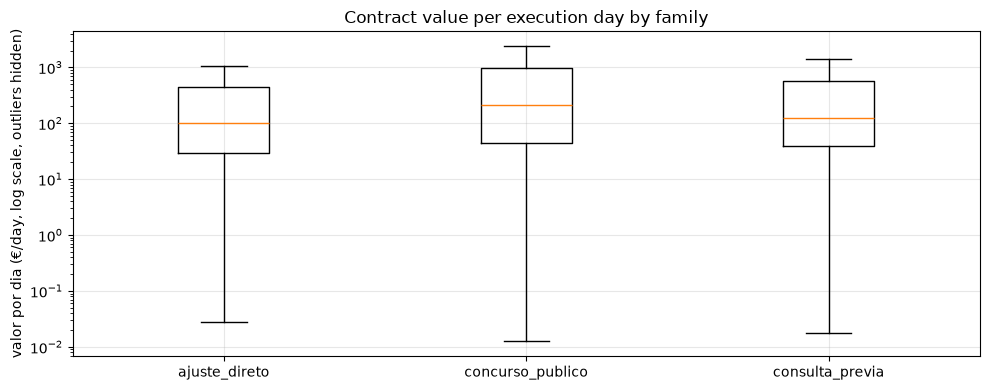

In [8]:
# Execution time and value per day by family (valor_por_dia only for 1..3650 days).
display(fam.group_by("family").agg(
    pl.col("prazo_execucao").median().alias("median_prazo_days"),
    pl.col("valor_por_dia").median().round(2).alias("median_eur_per_day"),
    pl.col("valor_por_dia").quantile(0.9).round(2).alias("p90_eur_per_day"),
    pl.col("valor_por_dia").is_not_null().mean().round(3).alias("share_defined"),
))
fd = fam.filter(pl.col("valor_por_dia") > 0)
fig, ax = plt.subplots()
ax.boxplot([fd.filter(pl.col("family") == f)["valor_por_dia"].to_numpy() for f in FAMILIES], tick_labels=FAMILIES, showfliers=False)
ax.set_yscale("log")
ax.set_ylabel("valor por dia (€/day, log scale, outliers hidden)")
ax.set_title("Contract value per execution day by family")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

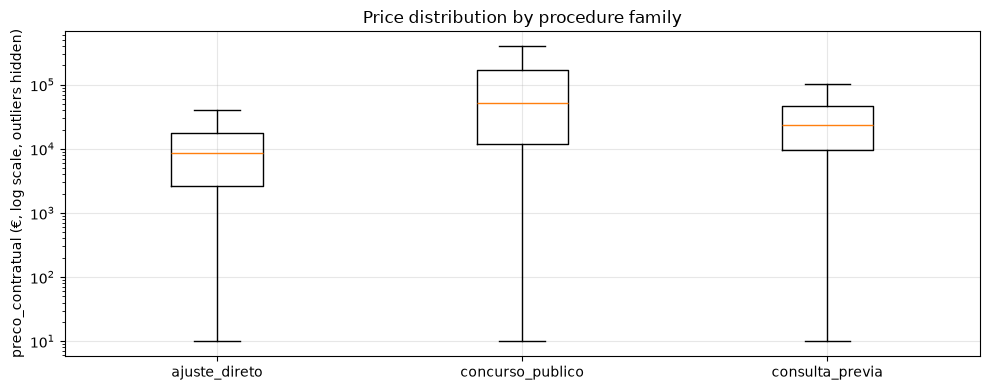

family,p10,p25,p50,p75,p90,p99
str,f64,f64,f64,f64,f64,f64
"""concurso_publico""",2319.0,11946.8,51985.0,167701.26,465882.0,3.7962e6
"""consulta_previa""",3307.28,9600.0,23290.0,47035.2,73910.72,159686.78
"""ajuste_direto""",403.36,2610.0,8763.05,18000.0,37950.0,390443.8


In [9]:
pos = fam.filter(pl.col("preco_contratual") > 0)
data = [pos.filter(pl.col("family") == f)["preco_contratual"].to_numpy() for f in FAMILIES]
fig, ax = plt.subplots()
ax.boxplot(data, tick_labels=FAMILIES, showfliers=False)
ax.set_yscale("log")
ax.set_ylabel("preco_contratual (€, log scale, outliers hidden)")
ax.set_title("Price distribution by procedure family")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
display(pos.group_by("family").agg(
    *[pl.col("preco_contratual").quantile(q).alias(f"p{int(q * 100)}") for q in (0.1, 0.25, 0.5, 0.75, 0.9, 0.99)]
))

In [10]:
# tipo_contrato can hold several "\n"-separated values; a contract counts once per value.
mix = (
    fam.with_columns(pl.col("tipo_contrato").str.split("\n"))
    .explode("tipo_contrato")
    .group_by("family", "tipo_contrato").len()
    .with_columns((pl.col("len") / pl.col("len").sum().over("family") * 100).round(1).alias("pct"))
    .pivot(on="family", index="tipo_contrato", values="pct")
    .sort("ajuste_direto", descending=True, nulls_last=True)
)
mix

/var/folders/qm/v8q4c7z96x3___vhx5_pxyc00000gn/T/ipykernel_70792/2238473746.py:4: DeprecationWarning: In Polars 2.0, the default behavior for `empty_as_null` will change to `False`. To keep the current behavior, explicitly set `empty_as_null=True`.
  .explode("tipo_contrato")


tipo_contrato,consulta_previa,ajuste_direto,concurso_publico
str,f64,f64,f64
"""Aquisição de bens móveis""",41.2,50.7,56.8
"""Aquisição de serviços""",45.7,45.1,28.0
"""Empreitadas de obras públicas""",11.2,3.1,12.9
"""Locação de bens móveis""",1.7,0.9,2.0
"""Concessão de serviços públicos""",0.0,0.0,0.2
"""Outros""",0.0,0.0,0.0
"""Concessão de obras públicas""",0.1,0.0,0.0
"""Sociedade""",0.0,0.0,0.0


In [11]:
divs = (
    fam.with_columns(pl.col("cpv").str.slice(0, 2).alias("cpv_div"))
    .group_by("family", "cpv_div").len()
    .with_columns((pl.col("len") / pl.col("len").sum().over("family") * 100).round(1).alias("pct"))
)
for f in FAMILIES:
    print(f"Top 10 CPV divisions: {f}")
    display(divs.filter(pl.col("family") == f).sort("len", descending=True).head(10))

Top 10 CPV divisions: ajuste_direto


family,cpv_div,len,pct
str,str,u32,f64
"""ajuste_direto""","""33""",59484,33.1
"""ajuste_direto""","""79""",14137,7.9
"""ajuste_direto""","""92""",12484,6.9
"""ajuste_direto""","""50""",11621,6.5
"""ajuste_direto""","""72""",8577,4.8
"""ajuste_direto""","""71""",7176,4.0
"""ajuste_direto""","""45""",5689,3.2
"""ajuste_direto""","""39""",4835,2.7
"""ajuste_direto""","""90""",4316,2.4


Top 10 CPV divisions: concurso_publico


family,cpv_div,len,pct
str,str,u32,f64
"""concurso_publico""","""33""",17908,28.4
"""concurso_publico""","""45""",8209,13.0
"""concurso_publico""","""30""",2668,4.2
"""concurso_publico""","""39""",2458,3.9
"""concurso_publico""","""15""",2270,3.6
"""concurso_publico""","""34""",2264,3.6
"""concurso_publico""","""71""",2150,3.4
"""concurso_publico""","""90""",2128,3.4
"""concurso_publico""","""79""",2081,3.3


Top 10 CPV divisions: consulta_previa


family,cpv_div,len,pct
str,str,u32,f64
"""consulta_previa""","""45""",7815,11.3
"""consulta_previa""","""79""",6115,8.9
"""consulta_previa""","""15""",4868,7.1
"""consulta_previa""","""33""",4743,6.9
"""consulta_previa""","""71""",4644,6.7
"""consulta_previa""","""39""",3413,5.0
"""consulta_previa""","""50""",3213,4.7
"""consulta_previa""","""30""",3168,4.6
"""consulta_previa""","""34""",2794,4.1


In [12]:
def concentration(df: pl.DataFrame, key: str) -> pl.DataFrame:
    """Per family: distinct entities, top-10 share of value and HHI of value shares."""
    by = df.group_by("family", key).agg(pl.col("preco_contratual").sum().alias("v"), pl.len().alias("n"))
    tot = by.with_columns((pl.col("v") / pl.col("v").sum().over("family")).alias("s"))
    return tot.group_by("family").agg(
        pl.len().alias("n_entities"),
        pl.col("s").sort(descending=True).head(10).sum().round(3).alias("top10_value_share"),
        (pl.col("s") ** 2).sum().round(4).alias("hhi_value"),
    )

print("Adjudicante (buyer) concentration by NIPC key:")
display(concentration(fam, "adjudicante_key"))
for f in FAMILIES:
    sub = fam.filter(pl.col("family") == f)
    top = (
        sub.group_by("adjudicante_key")
        .agg(pl.len().alias("n_contracts"), pl.col("preco_contratual").sum().round(0).alias("total_value"))
        .join(canonical_names(sub, prefix="adjudicante"), on="adjudicante_key", how="left")
        .sort("total_value", descending=True).head(20)
    )
    print(f"Top 20 buyers by value: {f}")
    display(top)

Adjudicante (buyer) concentration by NIPC key:


family,n_entities,top10_value_share,hhi_value
str,u32,f64,f64
"""concurso_publico""",2009,0.238,0.0229
"""consulta_previa""",4381,0.077,0.0017
"""ajuste_direto""",4280,0.288,0.012


Top 20 buyers by value: ajuste_direto


adjudicante_key,n_contracts,total_value,adjudicante_name
str,u32,f64,str
"""510103448""",4332,2.43777504e8,"""Unidade Local de Saúde de Coim…"
"""508481287""",2166,2.18042501e8,"""Unidade Local de Saúde de Sant…"
"""503933813""",478,1.95181646e8,"""Infraestruturas de Portugal, S…"
"""506362299""",21311,1.62804987e8,"""Instituto Português de Oncolog…"
"""508080142""",1405,1.4710009e8,"""Unidade Local de Saúde de São …"
"""515545180""",1510,1.29772188e8,"""Unidade Local Saúde de Braga, …"
"""509821197""",1586,1.19426097e8,"""Unidade Local de Saúde de São …"
"""508142156""",7693,9.7183637e7,"""Unidade Local de Saúde de Gaia…"
"""517392259""",558,9.6221414e7,"""Unidade Local de Saúde de Sant…"


Top 20 buyers by value: concurso_publico


adjudicante_key,n_contracts,total_value,adjudicante_name
str,u32,f64,str
"""503933813""",519,2.7453e9,"""Infraestruturas de Portugal, S…"
"""600010686""",483,3.53592017e8,"""Estado Maior da Força Aérea"""
"""512012032""",48,2.58086384e8,"""EDA - Electricidade dos Açores…"
"""513606084""",268,2.1373624e8,"""Águas do Norte, S. A."""
"""509540716""",385,1.86269053e8,"""SPMS - Serviços Partilhados do…"
"""508080142""",2177,1.85750539e8,"""Unidade Local de Saúde de São …"
"""511010435""",23,1.82823809e8,"""EEM - Empresa de Electricidade…"
"""514387130""",187,1.75277147e8,"""Águas do Tejo Atlântico, S. A."""
"""500051070""",246,1.64189165e8,"""Município de Lisboa"""


Top 20 buyers by value: consulta_previa


adjudicante_key,n_contracts,total_value,adjudicante_name
str,u32,f64,str
"""505187531""",188,2.5192071e7,"""Município de Cascais"""
"""503933813""",163,2.2713155e7,"""Infraestruturas de Portugal, S…"
"""506614913""",295,2.0686748e7,"""Município de Vila Franca de Xi…"
"""511010435""",106,2.0126097e7,"""EEM - Empresa de Electricidade…"
"""506173968""",274,1.9591322e7,"""Município do Seixal"""
"""500745943""",314,1.6523119e7,"""Município de Oeiras"""
"""506663264""",341,1.6272418e7,"""Município de Vila Nova de Fama…"
"""500051070""",287,1.6126875e7,"""Município de Lisboa"""
"""511228848""",927,1.56449e7,"""Serviço de Saúde da Região Aut…"


In [13]:
entries = entity_key(explode_entities(fam, "adjudicatarios", prefix="adjudicatarios"), prefix="adjudicatarios")
entries = entries.join(fam.select("idcontrato", "family", "preco_contratual"), on="idcontrato", how="left")
print(entries["adjudicatarios_key_source"].value_counts(sort=True))
# Multi-awardee contract value counted in full for each awardee.
print("Adjudicatario (supplier) concentration by key (includes name-fallback keys):")
display(concentration(entries, "adjudicatarios_key"))
print("Same, NIPC-keyed suppliers only:")
display(concentration(entries.filter(pl.col("adjudicatarios_key_source") == "nipc"), "adjudicatarios_key"))
fam_sets = {f: set(entries.filter((pl.col("family") == f) & (pl.col("adjudicatarios_key_source") == "nipc"))["adjudicatarios_key"]) for f in FAMILIES}
in_all = set.intersection(*fam_sets.values())
print(f"NIPC suppliers in all three families: {len(in_all):,} of {len(set.union(*fam_sets.values())):,}")
for f in FAMILIES: print(f"  only in {f}: {len(fam_sets[f] - set.union(*(v for k, v in fam_sets.items() if k != f))):,}")

shape: (2, 2)
┌───────────────────────────┬────────┐
│ adjudicatarios_key_source ┆ count  │
│ ---                       ┆ ---    │
│ str                       ┆ u32    │
╞═══════════════════════════╪════════╡
│ nipc                      ┆ 281095 │
│ name                      ┆ 33326  │
└───────────────────────────┴────────┘
Adjudicatario (supplier) concentration by key (includes name-fallback keys):


family,n_entities,top10_value_share,hhi_value
str,u32,f64,f64
"""ajuste_direto""",45035,0.111,0.0026
"""concurso_publico""",9328,0.165,0.0082
"""consulta_previa""",24030,0.029,0.0003


Same, NIPC-keyed suppliers only:


family,n_entities,top10_value_share,hhi_value
str,u32,f64,f64
"""ajuste_direto""",28486,0.123,0.0032
"""concurso_publico""",8362,0.171,0.0088
"""consulta_previa""",18589,0.031,0.0004


NIPC suppliers in all three families: 4,424 of 37,599
  only in ajuste_direto: 15,967
  only in concurso_publico: 1,629
  only in consulta_previa: 6,589


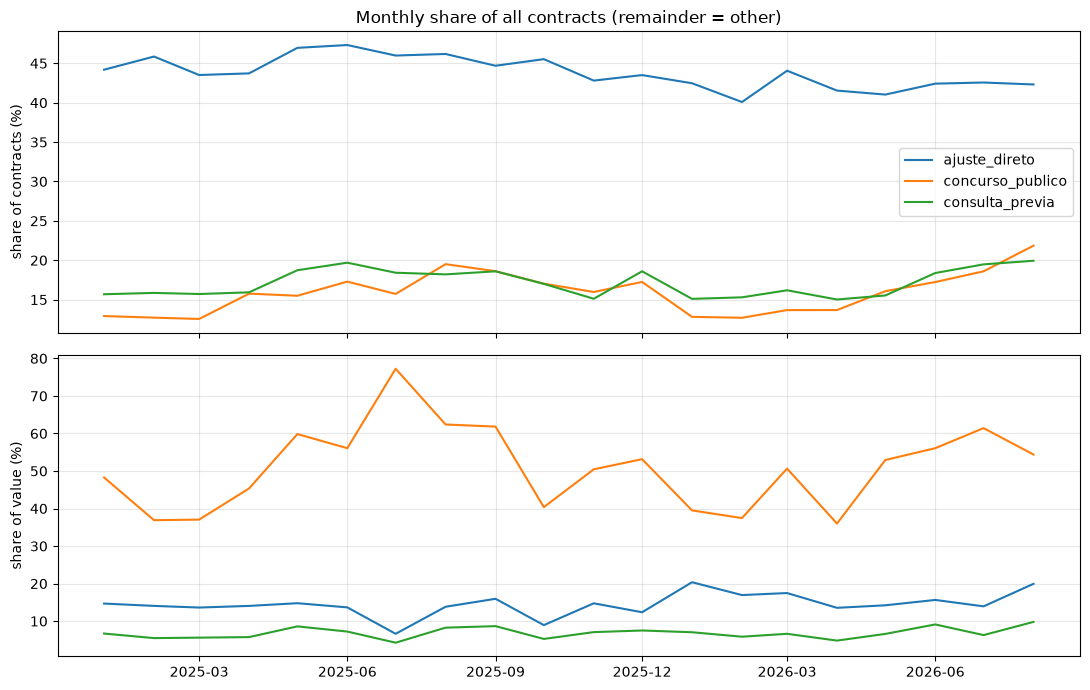

In [14]:
monthly = (
    contracts.filter(pl.col("data_celebracao").is_not_null())
    .with_columns(pl.col("data_celebracao").dt.truncate("1mo").alias("month"))
    .group_by("month", "family").agg(pl.len().alias("n"), pl.col("preco_contratual").sum().alias("v"))
    .with_columns(
        (pl.col("n") / pl.col("n").sum().over("month")).alias("count_share"),
        (pl.col("v") / pl.col("v").sum().over("month")).alias("value_share"),
    )
    .sort("month")
)
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for f in FAMILIES:
    m = monthly.filter(pl.col("family") == f)
    axes[0].plot(m["month"], m["count_share"] * 100, label=f)
    axes[1].plot(m["month"], m["value_share"] * 100, label=f)
axes[0].set_ylabel("share of contracts (%)")
axes[1].set_ylabel("share of value (%)")
axes[0].set_title("Monthly share of all contracts (remainder = other)")
axes[0].legend()
for ax in axes:
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
# NUTS II (first 4 chars of the first NUTS value) share per family, in %.
geo = (
    fam.with_columns(pl.col("nuts").str.split("\n").list.first().str.slice(0, 4).fill_null("n/a").alias("nuts2"))
    .group_by("family", "nuts2").len()
    .with_columns((pl.col("len") / pl.col("len").sum().over("family") * 100).round(1).alias("pct"))
    .pivot(on="family", index="nuts2", values="pct")
    .sort("ajuste_direto", descending=True, nulls_last=True)
)
geo

nuts2,ajuste_direto,consulta_previa,concurso_publico
str,f64,f64,f64
"""n/a""",49.0,51.5,51.1
"""PT11""",35.1,31.7,28.5
"""PT15""",5.0,4.8,5.2
"""PTZZ""",2.6,2.1,4.5
"""PT20""",2.2,0.7,1.8
"""PT19""",1.7,2.3,2.0
"""PT30""",1.4,3.9,2.8
"""PT1A""",1.0,1.0,1.8
"""PT1C""",0.9,1.0,0.8


## Synthesis

Shares below are of the three families combined (311,676 contracts priced ≥ €10); the remainder is `other`.

**Where they are similar**
- Supplier bases overlap: 4,424 NIPC suppliers appear in all three families (of 37,599 NIPC suppliers seen).
- Every family is spread over many buyers (2,009–4,381 NIPC-keyed adjudicantes), so no family depends on a handful of buyers by count.

**Where they differ**
- **Count vs value:** Ajuste Direto is 57.6 % of contracts but 19.3 % of value; Concurso público is 20.2 % of contracts but 71.7 % of value; Consulta Prévia is 22.1 % / 9.0 %.
- **Price levels:** median €8.8k (Ajuste Direto), €23.3k (Consulta Prévia), €52.0k (Concurso público). Concurso público's p99 is about €3.8M, against €390k for Ajuste Direto and €160k for Consulta Prévia — consistent with procedure thresholds pushing low values to direct award.
- **Buyer concentration (value, NIPC-keyed):** top-10 buyers hold 28.8 % of Ajuste Direto value (HHI 0.012), 23.8 % of Concurso público (HHI 0.023, driven by Infraestruturas de Portugal) and only 7.7 % of Consulta Prévia (HHI 0.002). Ajuste Direto's top buyers are health units (ULS), Concurso público's are infrastructure/utilities/defence, Consulta Prévia's are municipalities.
- **Supplier concentration:** Concurso público is the most concentrated (top-10 = 16.5 %, HHI 0.008); Consulta Prévia the most fragmented (2.9 %, 24,030 suppliers).
- **Supplier exclusivity:** 15,967 suppliers appear only in Ajuste Direto, 6,589 only in Consulta Prévia, 1,629 only in Concurso público.

Name-fallback suppliers (33,326 of 314k entries) are included in the first concentration table and excluded from the NIPC-only one; the conclusions hold either way.
- **Duration:** median `prazo_execucao` is 56 days for Ajuste Direto, 180 for Consulta Prévia and 300 for Concurso público; median value per day is €102, €127 and €216. Short contracts carry high €/day (Ajuste Direto 1–30 d: €336/day vs €19/day for 366–3650 d).


## Limitations

- `Ano` covers 2025–2026 only; edge months are partial.
- Supplier value counts a multi-awardee contract in full for each awardee.
- Name-fallback (`-` NIPC) suppliers are mostly individuals; similarity clustering may over- or under-merge, so a NIPC-only view is shown too.
- Prices are not adjusted for contract duration; CCP thresholds push low values to Ajuste Direto by design.
- Contracts priced below €10 are disregarded (see the per-family before/after cell); `valor_por_dia` uses only 1–3650-day durations.